In [1]:
import glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Settings ----------
CSV_PATH   = sorted(glob.glob('/kaggle/input/**/*.csv', recursive=True))[0]
TARGET     = 'Churn'
EPOCHS     = 100
LR         = 0.1
BATCH_SIZE = 32
SEED       = 42

# Random Forest settings
N_TREES           = 25
MAX_DEPTH         = 6
MIN_SAMPLES_SPLIT = 20
MIN_LEAF          = 5
N_THRESHOLDS      = 12   # candidate thresholds per feature (quantiles)

# ---------- Load ----------
df = pd.read_csv(CSV_PATH)
print("CSV:", CSV_PATH)
print("Shape:", df.shape)
df.head()

CSV: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df = df.copy()
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# TotalCharges فيها قيم فاضية (مسافات) فبنحولها لأرقام قبل dropna
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df = df.dropna().reset_index(drop=True)

# Target: Yes -> 1, No -> 0
y_all = (df[TARGET].astype(str).str.strip().str.lower() == 'yes').astype(float).values

# One-hot encode
X_df = pd.get_dummies(df.drop(columns=[TARGET]), drop_first=True, dtype=float)
feature_names = list(X_df.columns)
X_all = X_df.values.astype(float)

# 80/20 split with fixed SEED
rng_split = np.random.default_rng(SEED)
perm = rng_split.permutation(len(X_all))
n_train = int(0.8 * len(X_all))
tr_idx, te_idx = perm[:n_train], perm[n_train:]
X_train, X_test = X_all[tr_idx], X_all[te_idx]
y_train, y_test = y_all[tr_idx], y_all[te_idx]

# Standardize using TRAIN statistics only
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)
sigma[sigma == 0] = 1.0
X_train = (X_train - mu) / sigma
X_test  = (X_test  - mu) / sigma

# Bias term (last column)
X_train = np.hstack([X_train, np.ones((X_train.shape[0], 1))])
X_test  = np.hstack([X_test,  np.ones((X_test.shape[0], 1))])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (5625, 31) | Test: (1407, 31)
Churn rate  train: 0.264 | test: 0.273


In [3]:
# ================= Random Forest from scratch =================
def gini_from_sum(s, n):
    p = s / n
    return 2 * p * (1 - p)

def build_tree(X, y, depth, rng):
    n = len(y)
    if depth >= MAX_DEPTH or n < MIN_SAMPLES_SPLIT or y.min() == y.max():
        return {'p': float(y.mean())}
    d = X.shape[1]
    k = max(1, int(np.sqrt(d)))                       # random feature subset
    feats = rng.choice(d, size=k, replace=False)
    total = y.sum()
    best_score, best_f, best_t = np.inf, None, None
    for f in feats:
        col = X[:, f]
        thresholds = np.unique(np.quantile(col, np.linspace(0.1, 0.9, N_THRESHOLDS)))
        for t in thresholds:
            left = col <= t
            nl = int(left.sum()); nr = n - nl
            if nl < MIN_LEAF or nr < MIN_LEAF:
                continue
            sl = y[left].sum()
            score = (nl * gini_from_sum(sl, nl) + nr * gini_from_sum(total - sl, nr)) / n
            if score < best_score:
                best_score, best_f, best_t = score, f, t
    if best_f is None:
        return {'p': float(y.mean())}
    left = X[:, best_f] <= best_t
    return {'f': best_f, 't': best_t,
            'l': build_tree(X[left],  y[left],  depth + 1, rng),
            'r': build_tree(X[~left], y[~left], depth + 1, rng)}

def tree_predict(node, X):
    if 'p' in node:
        return np.full(len(X), node['p'])
    out = np.empty(len(X))
    m = X[:, node['f']] <= node['t']
    out[m]  = tree_predict(node['l'], X[m])
    out[~m] = tree_predict(node['r'], X[~m])
    return out

def build_forest(X, y, n_trees, seed):
    rng = np.random.default_rng(seed)
    trees = []
    for _ in range(n_trees):
        idx = rng.integers(0, len(y), len(y))         # bootstrap sample
        trees.append(build_tree(X[idx], y[idx], 0, rng))
    return trees

def forest_matrix(trees, X):
    return np.column_stack([tree_predict(t, X) for t in trees])   # (n, n_trees)

# ================= Build the forest (same in all notebooks) =================
t0 = time.time()
trees = build_forest(X_train[:, :-1], y_train, N_TREES, SEED)     # without bias column
P_train = forest_matrix(trees, X_train[:, :-1])
P_test  = forest_matrix(trees, X_test[:, :-1])
Z_train = np.hstack([P_train, np.ones((len(P_train), 1))])        # tree probs + bias
Z_test  = np.hstack([P_test,  np.ones((len(P_test), 1))])
print("Forest built in %.1fs | Z_train: %s" % (time.time() - t0, Z_train.shape))

# ================= Trainable part: weighted voting =================
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

def predict_proba(Z, w):
    return sigmoid(Z @ w)

def predict(Z, w, threshold=0.5):
    return (predict_proba(Z, w) >= threshold).astype(float)

def loss_fn(Z, y, w):
    p = np.clip(predict_proba(Z, w), 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def gradient(Z, y, w):
    p = predict_proba(Z, w)
    return Z.T @ (p - y) / len(y)

def classification_metrics(y_true, y_pred):
    tp = np.sum((y_pred == 1) & (y_true == 1))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    acc  = np.mean(y_pred == y_true)
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    return acc, prec, rec, f1

Forest built in 1.7s | Z_train: (5625, 26)


In [4]:
OPT_NAME = 'Adam'
B1, B2, EPS = 0.9, 0.999, 1e-8
w = np.zeros(Z_train.shape[1])
m = np.zeros_like(w)
v = np.zeros_like(w)
step = 0
rng = np.random.default_rng(SEED)
n = len(y_train)
loss_history = []
t0 = time.time()

for epoch in range(EPOCHS):
    perm = rng.permutation(n)
    for s in range(0, n, BATCH_SIZE):
        b = perm[s:s + BATCH_SIZE]
        g = gradient(Z_train[b], y_train[b], w)
        step += 1
        m = B1 * m + (1 - B1) * g
        v = B2 * v + (1 - B2) * (g ** 2)
        m_hat = m / (1 - B1 ** step)
        v_hat = v / (1 - B2 ** step)
        w = w - LR * m_hat / (np.sqrt(v_hat) + EPS)
    loss_history.append(loss_fn(Z_train, y_train, w))

train_time = time.time() - t0
print("Done in %.1fs" % train_time)

Done in 0.8s


Optimizer : Adam
Train time: 0.8s
Accuracy  : 0.7719
Precision : 0.5763
Recall    : 0.6198
F1        : 0.5972
Test Loss : 0.4542
Final Train Loss: 0.3992
Reference - plain RF average vote accuracy: 0.7804

Paste this into the final cell:
'Adam': {'Accuracy': 0.7719, 'Precision': 0.5763, 'Recall': 0.6198, 'F1': 0.5972, 'Loss': 0.4542},


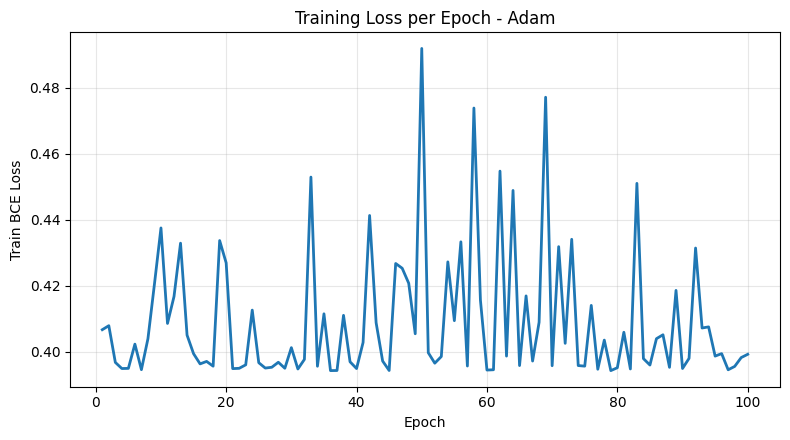

In [5]:
y_pred = predict(Z_test, w)
acc, prec, rec, f1 = classification_metrics(y_test, y_pred)
test_loss = loss_fn(Z_test, y_test, w)

print("=" * 40)
print("Optimizer :", OPT_NAME)
print("Train time: %.1fs" % train_time)
print("Accuracy  : %.4f" % acc)
print("Precision : %.4f" % prec)
print("Recall    : %.4f" % rec)
print("F1        : %.4f" % f1)
print("Test Loss : %.4f" % test_loss)
print("Final Train Loss: %.4f" % loss_history[-1])
print("=" * 40)

# reference: plain RF (simple average of trees, no learned weights)
rf_pred = (P_test.mean(axis=1) >= 0.5).astype(float)
print("Reference - plain RF average vote accuracy: %.4f" % np.mean(rf_pred == y_test))

# ready-to-paste line for the final comparison cell
print("\nPaste this into the final cell:")
print("'%s': {'Accuracy': %.4f, 'Precision': %.4f, 'Recall': %.4f, 'F1': %.4f, 'Loss': %.4f}," %
      (OPT_NAME, acc, prec, rec, f1, test_loss))

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(loss_history) + 1), loss_history, linewidth=2)
plt.title("Training Loss per Epoch - %s" % OPT_NAME)
plt.xlabel("Epoch")
plt.ylabel("Train BCE Loss")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()